# Mouse gastrulation

Load paired RNA and ATAC observations, train COATI, and show the learned flow on a UMAP. This short example uses all four observed stages. The default settings are shared with the Python script.

In [1]:
from pathlib import Path
import os
import json
import uuid
import anndata as ad
import numpy as np
import matplotlib.pyplot as plt
import coati as ct

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
project_dir = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir())
data_dir = Path(os.environ.get(
    "COATI_GASTRULATION_DATA", project_dir.parent / "TraInfBench/data/processed/gastrulation",
))
settings = json.loads((project_dir / "examples/gastrulation.json").read_text())

## Load the data

Use the prepared `rna.h5ad` and `atac.h5ad` files from the gastrulation dataset. Set `COATI_GASTRULATION_DATA` if they are stored elsewhere.

RNA PCA and ATAC LSI features in `X_latent` are already normalized. Use these features for training and the supplied `X_umap` for display. `prepare_anndata` standardizes metadata to `celltype`, `time` and `barcode` on a working copy; unannotated cells remain `unknown`.

In [2]:
rna = ad.read_h5ad(data_dir / "rna.h5ad")
atac = ad.read_h5ad(data_dir / "atac.h5ad")
assert rna.obs_names.is_unique and rna.obs_names.equals(atac.obs_names)
np.testing.assert_array_equal(rna.obs["time_point_processed"], atac.obs["time_point_processed"])
np.testing.assert_array_equal(rna.obs["stage"], atac.obs["stage"])
cells = ct.prepare_anndata(
    rna, use_rep="X_latent", time_key="time_point_processed",
    celltype=rna.obs["celltype"].astype(object).fillna("unknown"),
    secondary=atac.obsm["X_latent"], secondary_key="X_atac", warn=False,
)
cells.obs.groupby(["stage", "time"], observed=True).size().rename("Cells").to_frame()

,,Cells
stage,time,
E7.5,0.0,9018
E8.0,1.0,7796
E8.5,2.0,11470
E8.75,2.5,7219


## Train COATI

This example uses paired modalities and allows changing population mass. COATI fits the cross-modal map and then the primary vector field. Defaults are stored in the example configuration.

In [3]:
config = ct.Config(**settings["training"])
run_dir = project_dir / "outputs" / ("gastrulation-" + uuid.uuid4().hex[:8])
result = ct.train_vector_field(cells, config, output_dir=run_dir)
print("Model:", result.output_dir.relative_to(project_dir))
print("Observed times:", result.data.times)

Model: outputs/gastrulation-5f62a4f1
Observed times: [0.  1.  2.  2.5]


## Show the UMAP flow

Colors show the supplied cell types at the selected stage. Lines show the learned COATI velocities projected onto the existing RNA UMAP.

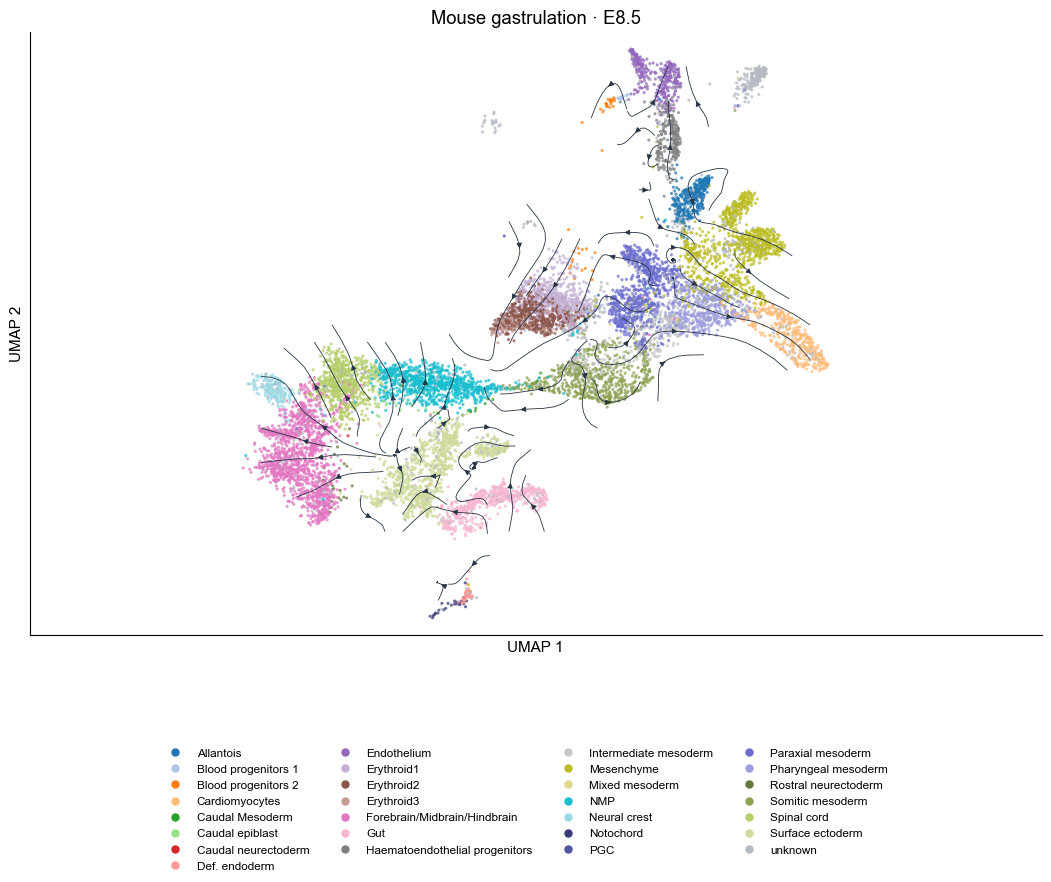

In [4]:
stage = settings["plot_stage"]
stage_cells = cells[cells.obs["stage"] == stage].copy()
colors = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
palette = dict(zip(stage_cells.obs["celltype"].cat.categories, colors))
palette["unknown"] = "#b5bac2"
fig, ax = plt.subplots(figsize=(11, 9))
result.plot_velocity(
    stage_cells, color="celltype", style="stream", palette=palette,
    point_size=5, alpha=.75, density=1.2, linewidth=.6, arrow_size=.8, ax=ax,
    title=f"Mouse gastrulation · {stage}",
)
legend = ax.get_legend()
fig.legend(legend.legend_handles, [t.get_text() for t in legend.get_texts()],
           loc="lower center", ncol=4, frameon=False, fontsize=8.5, markerscale=1.2)
legend.remove()
ax.set_xticks([])
ax.set_yticks([])
fig.subplots_adjust(left=.06, right=.98, bottom=.27, top=.94)
plt.show()

The same workflow is available as a Python script:

```bash
python examples/run_gastrulation.py --data-dir /path/to/gastrulation
```

This short run demonstrates data preparation, training and visualization.